# 04 · Analysis: EDA → ETL → ML

**Run order:** `01_globalization` → `02_acceleration_utility` → `03_top_speed_utility` → **`04_analysis`** → `05_three_models`.
The first run builds `Results/cohort_events.pkl` (~20 s); later runs read it in a second.

| part | question | built on |
|---|---|---|
| **A · EDA** | What do the 30 runs look like before any kinematics? | `sprint_summary.py` |
| **B · ETL** | How does each run become one row and one stride cycle? | `cohort.py`, `stride.py` |
| **C · ML** | Does any movement measure predict a new runner's top speed beyond sex? | `sprint_pipeline.py` §6, §9–10 |
| **D · OpenSim (optional)** | Muscle–tendon stretch, if `OpenSim/Out/mtu_summary.csv` exists | skipped if absent |

Every model is scored **leave-one-out**: fit on 29 runners, predict the 30th, repeat. Anything learned from the
data (standardisation, PCA axes, ridge penalty) is refit inside each fold.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV

import cohort as C                    # ETL: one row + one cycle per runner (cached)
import sprint_pipeline as SP          # angles, fPCA, leave-one-out helpers
from project_paths import PATHS

data = C.load()                       # C.load(rebuild=True) after changing stride.py or cohort.py
F, cycles, runs = data["features"], data["cycles"], data["runs"]
SEX_COL = SP.SEX_COL                  # grey = men, orange = women, the colours used in every figure
print(f"{len(F)} runners: {(F.sex == 'M').sum()} men, {(F.sex == 'F').sum()} women")

30 runners: 15 men, 15 women


---
# A · EDA: the runs before any kinematics

## A1 · Data quality first
`missed_contacts` counts places where the same foot appears twice in a row, i.e. a step the detector missed.
`phase_spread` is how far (in % of the stride) the knee's peak flexion moves between the 5 top-speed strides;
a large value means the strides being averaged do not line up.

In [2]:
qa = F[["missed_contacts", "n_strides", "phase_spread", "steps_to_60m"]]
qa[(qa.missed_contacts > 0) | (qa.phase_spread > 10)]

,missed_contacts,n_strides,phase_spread,steps_to_60m
runner,,,,
SB111,4,5,21.0,27
SB155,3,5,3.0,28
SB25,0,5,13.0,34
SB74,7,5,13.0,26


## A2 · Headline numbers by sex

In [3]:
cols = ["top_speed_ms", "time_to_60m_s", "time_to_top_speed_s", "distance_at_top_speed_m",
        "steps_to_top_speed", "block_time_s", "avg_stride_length_m", "avg_step_frequency_hz"]
F.groupby("sex")[cols].agg(["mean", "std", "min", "max"]).T.round(2)

sex                               F      M
top_speed_ms            mean   7.52   8.70
                        std    0.43   0.40
                        min    6.39   8.10
                        max    8.23   9.35
time_to_60m_s           mean   9.04   7.88
                        std    0.51   0.34
                        min    8.40   7.38
                        max   10.60   8.58
time_to_top_speed_s     mean   6.29   5.50
                        std    1.43   1.20
                        min    4.05   3.70
                        max    8.38   7.73
distance_at_top_speed_m mean  40.42  40.17
                        std   10.65  10.31
                        min   23.70  24.00
                        max   55.70  61.30
steps_to_top_speed      mean  25.20  22.33
                        std    5.76   5.52
                        min   15.00  13.00
                        max   32.00  31.00
block_time_s            mean   0.28   0.25
                        std    0.06   0.02
                        min    0.18   0.20
                        max    0.43   0.28
avg_stride_length_m     mean   3.37   3.84
                        std    0.22   0.42
                        min    3.06   3.44
                        max    3.71   4.76
avg_step_frequency_hz   mean   4.13   4.28
                        std    0.30   0.27
                        min    3.34   3.83
                        max    4.46   4.74

## A3 · Speed over the run

Every runner's smoothed speed against distance. The dot marks top speed.

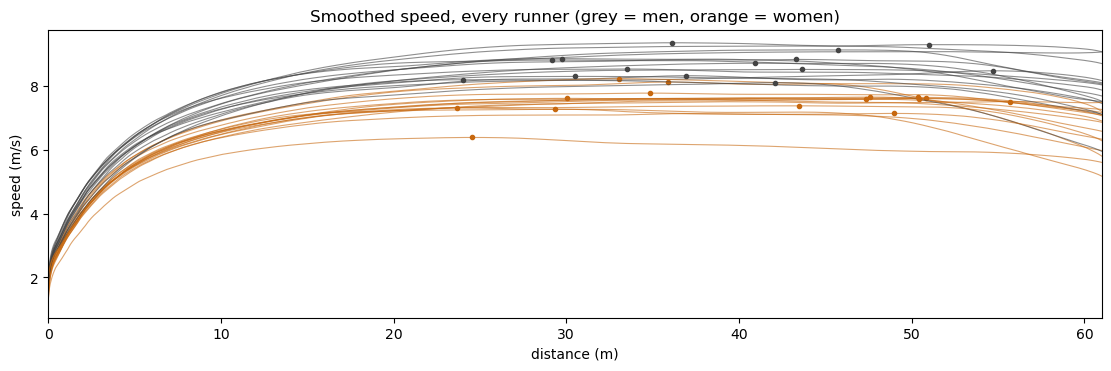

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.6), constrained_layout=True)
for rid, run in runs.items():
    k = int(np.argmax(run.speed))
    ax.plot(run.distance, run.speed, color=SEX_COL[F.sex[rid]], lw=0.8, alpha=0.6)
    ax.plot(run.distance[k], run.speed[k], "o", color=SEX_COL[F.sex[rid]], ms=3)
ax.set(xlim=(0, 61), xlabel="distance (m)", ylabel="speed (m/s)",
       title="Smoothed speed, every runner (grey = men, orange = women)");

## A4 · Why sex is the baseline

Top speed against stature: the two sexes form two clouds. Anything that differs between men and women (height,
limb length, contact time) will correlate with speed in the pooled data without saying anything about technique.

Top speed is also, by definition, stride length × stride frequency (right panel). Those two are a *breakdown* of
speed, not predictors of it, so they are kept out of the models in part C.

stride length x frequency vs top speed: r = 0.917


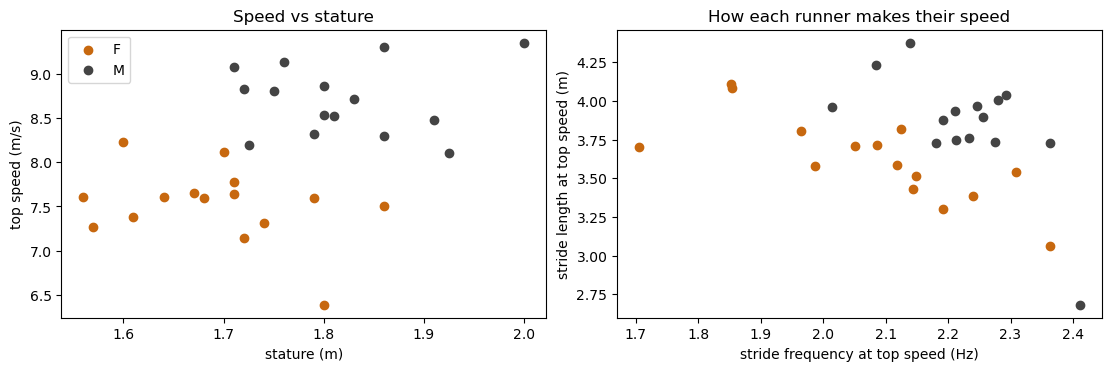

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for s, g in F.groupby("sex"):
    ax[0].scatter(g.height_m, g.top_speed_ms, color=SEX_COL[s], label=s)
    ax[1].scatter(g.top_stride_frequency_hz, g.top_stride_length_m, color=SEX_COL[s], label=s)
ax[0].set(xlabel="stature (m)", ylabel="top speed (m/s)", title="Speed vs stature")
ax[1].set(xlabel="stride frequency at top speed (Hz)", ylabel="stride length at top speed (m)",
          title="How each runner makes their speed")
ax[0].legend()
check = F.top_stride_length_m * F.top_stride_frequency_hz
print(f"stride length x frequency vs top speed: r = {np.corrcoef(check, F.top_speed_ms)[0, 1]:.3f}")

---
# B · ETL: from a run to one row

**Extract.** `sprint_summary.summarize()` gives each run's contacts (from `stride.py`), smoothed speed and
distance. **Transform.** Keep the 5 *clean* right-foot strides nearest top speed (one left contact between two
right touchdowns, 22–40 frames long), compute 13 joint angles, stretch each stride to 101 points (0 % = right
touchdown), average and smooth. **Load.** Scalars from that cycle plus the run summary → one row per runner.

## B1 · The strides kept for one runner

In [6]:
RUNNER = "SB80"
run = runs[RUNNER]
fs = run.trial["fs"]
strides = C.top_speed_strides(run)
pd.DataFrame([{"right_touchdown": a.touchdown, "left_touchdown": m.touchdown, "next_right_touchdown": b.touchdown,
               "stride_ms": (b.touchdown - a.touchdown) / fs * 1000,
               "speed_ms": run.speed[a.touchdown]} for a, m, b in strides]).round(2)

,right_touchdown,left_touchdown,next_right_touchdown,stride_ms,speed_ms
0,388,401,416,466.67,7.12
1,416,430,444,466.67,7.11
2,444,459,474,500.00,7.13
3,474,489,505,516.67,7.13
4,505,522,540,583.33,7.00


## B2 · The cycles: cohort mean ± 1 SD, fast vs slow

Four of the 13 angles. Blue = the 5 fastest runners' mean, red = the 5 slowest (`SP.fast_vs_slow_angles`).

fastest: ['SB50', 'SB101', 'SB82', 'SB155', 'SB061'] | slowest: ['SB81', 'SB110', 'SB153', 'SB80', 'SB202']


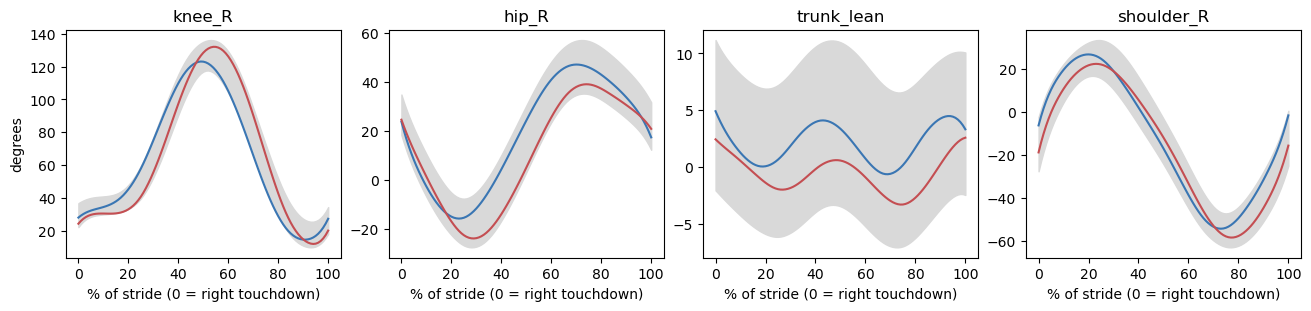

In [7]:
table, fast, slow, fast_ids, slow_ids = SP.fast_vs_slow_angles(cycles, F.top_speed_ms.to_dict(), n=5)
pct = np.arange(101)
fig, axes = plt.subplots(1, 4, figsize=(13, 3), constrained_layout=True)
for ax, name in zip(axes, ["knee_R", "hip_R", "trunk_lean", "shoulder_R"]):
    j = SP.ANGLE_NAMES.index(name)
    allc = np.stack([c[:, j] for c in cycles.values()])
    ax.fill_between(pct, allc.mean(0) - allc.std(0), allc.mean(0) + allc.std(0), color="0.85")
    ax.plot(pct, fast[:, j], color=SP.COL_FAST)
    ax.plot(pct, slow[:, j], color=SP.COL_SLOW)
    ax.set(title=name, xlabel="% of stride (0 = right touchdown)")
axes[0].set_ylabel("degrees")
print("fastest:", fast_ids, "| slowest:", slow_ids)

## B3 · The loaded table (first rows)

In [8]:
F.head()

,time_to_60m_s,top_speed_ms,time_to_top_speed_s,distance_at_top_speed_m,steps_to_top_speed,steps_to_60m,avg_stride_length_m,avg_stride_frequency_hz,avg_step_frequency_hz,block_time_s,...,shoulder_hi_ROM,shoulder_hi_mean,shoulder_lo_ROM,shoulder_lo_mean,elbow_hi_ROM,elbow_hi_mean,elbow_lo_ROM,elbow_lo_mean,trunk_lean_mean,trunk_lean_ROM
runner,,,,,,,,,,,,,,,,,,,,,
SB061,7.717,8.86,4.150,29.8,16,31,3.97,2.05,4.09,0.250,...,101.747527,-11.246780,80.468135,-4.318317,122.901078,64.407417,111.192438,66.436204,7.144160,6.842689
SB101,7.417,9.30,6.433,51.0,29,33,3.69,2.28,4.56,0.233,...,99.100203,-7.834357,85.178294,-13.956019,97.160915,70.276262,73.799672,72.048414,1.596985,7.953565
SB102,8.883,7.61,4.850,30.1,21,38,3.15,2.22,4.44,0.217,...,99.177772,-15.598659,78.172136,-13.449152,65.087141,59.019853,47.975432,57.730116,-1.896894,6.642453
SB110,9.350,7.31,4.050,23.7,17,39,3.06,2.21,4.42,0.283,...,86.578891,-7.043926,67.840719,-4.001608,77.483404,50.626608,47.587540,64.089428,6.314583,5.735796
SB111,8.200,8.32,5.350,36.9,17,27,4.59,1.92,3.83,0.267,...,77.357271,-5.600483,74.780088,-19.721868,79.369136,43.736787,72.775381,63.616204,6.281702,7.377372


---
# C · ML: does movement predict a new runner's speed beyond sex?

**Target**: top speed (peak of the smoothed speed curve). **Baseline**: sex alone; it is known without any motion
capture, so a movement model has to beat it to be worth the suit.

## C1 · Whole-body movement modes (fPCA, descriptive)

PCA on the 13 smoothed angle curves (each angle standardised). `r` = correlation with top speed; `partial` = the
same with sex held constant.

In [9]:
fp = SP.run_angle_fpca(cycles, n_components=6)
y_fp = F.loc[fp["pids"], "top_speed_ms"].to_numpy()
male = (F.loc[fp["pids"], "sex"] == "M").to_numpy(float)
resid = lambda v: v - np.polyval(np.polyfit(male, v, 1), male)     # remove the sex difference
pd.DataFrame({"variance_%": fp["explained_var"],
              "r": [np.corrcoef(s, y_fp)[0, 1] for s in fp["scores"].T],
              "partial_given_sex": [np.corrcoef(resid(s), resid(y_fp))[0, 1] for s in fp["scores"].T]},
             index=[f"PC{k + 1}" for k in range(6)]).round(2)

,variance_%,r,partial_given_sex
PC1,44.08,-0.19,-0.02
PC2,18.81,-0.44,-0.50
PC3,7.93,0.06,-0.02
PC4,6.11,0.27,0.05
PC5,4.27,0.18,0.21
PC6,2.86,-0.27,-0.02


## C2 · The model ladder

* Linear models are scored with `SP.loo_r2_fast` (exact leave-one-out in one fit).
* **p for the gain over sex**: shuffle the added variable *within each sex* 5,000 times and count how often the
  shuffled model scores at least as well. Holm-corrected across the three gain tests.
* fPCA models refit the PCA axes in every fold (`SP.fpca_fold_transform`) and use ridge regression. No p-value:
  the question for them is only whether they beat sex.

The three gain tests are the variables the earlier screen already flagged (stature, knee range of motion,
contact time), re-measured on the corrected strides. They are exploratory, not pre-registered.

In [10]:
y = F.top_speed_ms.to_numpy()
male = (F.sex == "M").to_numpy(float)
knee = F[["knee_hi_ROM", "knee_lo_ROM"]].to_numpy()
height, contact = F.height_m.to_numpy(), F.top_contact_ms.to_numpy()
rng = np.random.default_rng(1)                                   # seed 1, as in every ledger p-value
N_PERM = 5000

def gain_p(extra):
    """Within-sex permutation p for adding `extra` to sex."""
    observed = SP.loo_r2_fast(np.column_stack([male, extra]), y)
    groups = [np.where(male == s)[0] for s in (0, 1)]
    hits = 0
    for _ in range(N_PERM):
        idx = np.arange(len(y))
        for g in groups:
            idx[g] = rng.permutation(g)
        hits += SP.loo_r2_fast(np.column_stack([male, np.asarray(extra)[idx]]), y) >= observed
    return (hits + 1) / (N_PERM + 1)

def fpca_r2(with_sex):
    """Ridge on 6 fold-refit fPCA scores (+ sex), leave-one-out."""
    pids = list(F.index)
    base = SP.fpca_fold_transform(cycles, pids)
    def transform(tr, te):
        a, b = base(tr, te)
        return (np.column_stack([male[tr], a]), np.column_stack([male[te], b])) if with_sex else (a, b)
    pred = SP.loo_predict(None, y, model_fn=lambda: RidgeCV(alphas=np.logspace(-2, 3, 20)), transform=transform)
    return SP.fit_metrics(y, pred)["LOO_R2"]

rows = [("intercept only", SP.loo_r2_fast(np.zeros((len(y), 0)), y), np.nan),
        ("sex", SP.loo_r2_fast(male, y), np.nan),
        ("stature", SP.loo_r2_fast(height, y), np.nan),
        ("knee ROM + stature", SP.loo_r2_fast(np.column_stack([knee, height]), y), np.nan),
        ("fPCA, ridge (fold refit)", fpca_r2(False), np.nan),
        ("sex + stature", SP.loo_r2_fast(np.column_stack([male, height]), y), gain_p(height)),
        ("sex + knee ROM + stature", SP.loo_r2_fast(np.column_stack([male, knee, height]), y),
         gain_p(np.column_stack([knee, height]))),
        ("sex + top-speed contact time", SP.loo_r2_fast(np.column_stack([male, contact]), y), gain_p(contact)),
        ("sex + fPCA, ridge (fold refit)", fpca_r2(True), np.nan)]
models = pd.DataFrame(rows, columns=["model", "LOO_R2", "gain_p"]).set_index("model")
models["gain_over_sex"] = models.LOO_R2 - models.loc["sex", "LOO_R2"]
tested = models.gain_p.dropna().sort_values()                    # Holm step-down
holm = np.maximum.accumulate([p * (len(tested) - i) for i, p in enumerate(tested)])
models.loc[tested.index, "gain_p_holm"] = np.minimum(holm, 1)
models.round(4)

,LOO_R2,gain_p,gain_over_sex,gain_p_holm
model,,,,
intercept only,-0.0702,NaN,-0.7121,NaN
sex,0.6419,NaN,0.0000,NaN
stature,0.0972,NaN,-0.5447,NaN
knee ROM + stature,0.0310,NaN,-0.6109,NaN
"fPCA, ridge (fold refit)",0.1022,NaN,-0.5398,NaN
sex + stature,0.6029,0.9404,-0.0390,1.0000
sex + knee ROM + stature,0.5152,0.9712,-0.1267,1.0000
sex + top-speed contact time,0.7264,0.0008,0.0844,0.0024
"sex + fPCA, ridge (fold refit)",0.6671,NaN,0.0252,NaN


## C3 · Did the corrected strides change anything?

The same models in the previous workbook (`Results/sprint_results.xlsx`, built on the old stride finder:
foot-centre minima around the *raw* speed peak). Same target, same runners; only the strides differ.

In [11]:
old = pd.read_excel(PATHS.results / "sprint_results.xlsx", sheet_name="models").set_index("model").loo_r2
same = {"sex": "sex", "stature": "height", "knee ROM + stature": "knee ROM + height",
        "sex + knee ROM + stature": "sex + knee ROM + height"}
pd.DataFrame({"old_strides": [old[o] for o in same.values()],
              "new_strides": models.loc[list(same), "LOO_R2"].to_numpy()}, index=list(same)).round(3)

,old_strides,new_strides
sex,0.641,0.642
stature,0.097,0.097
knee ROM + stature,0.256,0.031
sex + knee ROM + stature,0.600,0.515


## C4 · Robustness: drop the runners with detector problems

Contact time is the one variable that now adds to sex, and it comes straight from the contact detector. So the
test is repeated without the 3 runners whose contacts the detector partly missed (`missed_contacts > 0`:
SB74, SB111, SB155).

In [12]:
keep = (F.missed_contacts == 0).to_numpy()
r2_sex = SP.loo_r2_fast(male[keep], y[keep])
r2_ct = SP.loo_r2_fast(np.column_stack([male, contact])[keep], y[keep])
print(f"{keep.sum()} runners: sex {r2_sex:.3f} -> sex + contact time {r2_ct:.3f} (gain {r2_ct - r2_sex:+.3f})")

27 runners: sex 0.656 -> sex + contact time 0.760 (gain +0.104)


## C5 · Reading the results

* **Top speed is a plateau for most runners** (part A3), so its exact frame falls anywhere from 24 to 61 m;
  the 5 strides around it are what the models use, not a single frame.
* **Sex is still the baseline to beat.** It alone predicts a new runner's top speed at LOO R² 0.64, the same
  as before: the target did not change, only the strides.
* **Whole-body movement modes do not beat it.** fPCA alone scores 0.10; with sex 0.67, a small gain that is not
  tested formally. PC2 is the one mode that still tracks speed with sex held constant (partial r −0.50).
* **The old knee lead does not survive the corrected strides.** Knee ROM + stature falls from 0.26 to 0.03, and
  adding it to sex makes predictions worse.
* **Top-speed contact time does add to sex** (0.64 → 0.73, within-sex p = 0.0008, Holm-corrected 0.0024), and
  the gain holds (+0.10) without the 3 runners with detector problems. Read it carefully: contact time is partly a *consequence* of speed (a faster
  runner covers the same contact length sooner), so this is a timing association, not a technique cause. It
  is also the variable most exposed to the 60 Hz limit (each frame is 16.7 ms of a ~95 ms contact).

These numbers come from this notebook's own output; re-run it after any change to `stride.py` or `cohort.py`.

---
# D · OpenSim (optional)

Muscle–tendon stretch from OpenSim inverse kinematics on the gait2392 model. Kinematic only: no mass, no force.
This section runs only if `OpenSim/Out/mtu_summary.csv` exists. To regenerate it you need OpenSim 4.5 and
`PYTHONPATH=. python "(Deprecated)/sprint_opensim.py"` (about 30 min).

Since 2026-11-14 the CSV comes from notebook 07: the whole-trial Scale/IK/MuscleAnalysis artifacts are reused
and the stride summary uses the `stride.py` windows (the old-window CSV is kept as `mtu_summary_oldstrides.csv`;
the per-trial viewer is `OpenSim/viewer.html`).

In [13]:
mtu_path = PATHS.opensim / "Out" / "mtu_summary.csv"
if not mtu_path.exists():
    print("no OpenSim output: section skipped")
else:
    mtu = pd.read_csv(mtu_path).set_index("runner_id").reindex(F.index)
    # Same QA rule as the old report: a poor IK fit gives untrustworthy muscle lengths.
    ok = (mtu.knee_R_r_osim >= 0.95) & (mtu.hip_R_r_osim >= 0.95) & (mtu.ik_rms_mm <= 35)
    print(f"IK fit passes QA for {ok.sum()} of {len(mtu)} runners")
    x = mtu.bflh_lengthen_Lps.to_numpy()                       # H6: hamstring stretch speed, late swing
    m = ok.to_numpy() & np.isfinite(x)
    r2_s = SP.loo_r2_fast(male[m], y[m])
    r2_h = SP.loo_r2_fast(np.column_stack([male, x])[m], y[m])
    print(f"H6 (biceps femoris lengthening speed), {m.sum()} runners: sex {r2_s:.3f} -> + H6 {r2_h:.3f}")

IK fit passes QA for 25 of 30 runners
H6 (biceps femoris lengthening speed), 25 runners: sex 0.716 -> + H6 0.694


## Self-checks

In [14]:
assert len(F) == 30 and (F.n_strides == C.N_STRIDES).all()
assert abs(F.loc["SB80", "top_speed_ms"] - 7.14) < 0.005                  # same target as sprint_summary
assert abs(models.loc["sex", "LOO_R2"] - old["sex"]) < 0.005             # sex baseline unchanged
assert np.isfinite(np.stack(list(cycles.values()))).all()
print("analysis checks passed")

analysis checks passed
